# Annotating cell types with supervised fine-tuning

We annotate cells through supervised fine-tuning (SFT) of scCAFM's EFM first-token cell-state embedding. SFT updates the complete EFM embedding module, transformer backbone and cell-type classifier.

Pretrained SFM supplies gene orders in evaluation mode, following the EFM pretraining pipeline. For annotation, the first token attends to the complete observed sequence at every transformer layer. Gene queries retain their triangular attention mask and attend to the first token. The classifier uses the resulting gene-aware cell-state token.

This annotation-specific attention pattern reuses the pretrained parameters. It changes information flow and is not autoregressive. The original causal EFM forward pass and cached generation retain their existing behavior.

This tutorial evaluates known cell types using all PBMC cells in a stratified 70:30 training/test split. It is not an unseen-cell-type detector or a donor-transfer benchmark. Softmax confidence scores are not calibrated probabilities of biological correctness.

## 1. Set up the tutorial

Model files are read from `assets/`. The full PBMC file is copied unchanged into `tutorial_data/cell_type_annotation/pbmc.h5ad`. All paths are relative to the repository. Sampling, preprocessing and fitting operate in memory; the file on disk is not modified.


In [1]:
from pathlib import Path
import warnings

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from sklearn.model_selection import train_test_split

from sccafm import (
    CellTypeAnnotator,
    ScPreprocessor,
    evaluate_cell_type_annotation,
    load_vocab_json,
    resolve_model_assets,
)

warnings.filterwarnings("ignore", message="Mismatch dtype between input and weight")

REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == "docs":
    REPO_ROOT = REPO_ROOT.parent
MODEL_SOURCE = REPO_ROOT / "assets"
DATA_PATH = REPO_ROOT / "tutorial_data" / "cell_type_annotation" / "pbmc.h5ad"
LABEL_KEY = "cell_type"
RANDOM_STATE = 42

assets = resolve_model_assets(MODEL_SOURCE)
token_dict = load_vocab_json(assets.vocab)
print("Tutorial paths and model assets are ready.")


Tutorial paths and model assets are ready.


## 2. Examine the PBMC data

The file contains 68,579 human PBMCs, 32,738 genes and 11 annotated cell types. Some classes are rare: the complete file contains 97 CD4+ T Helper2 cells. We construct a new stratified 70:30 split across all cells; the file's original `split` column is retained as provenance and is not used in this tutorial.

### Prepare your own annotated data

- Store non-negative raw counts in `adata.X` and unique cell/gene identifiers in `obs_names` and `var_names`.
- Put gene symbols in `var_names`, or pass the gene-symbol column as `gene_key` when fitting.
- Put training annotations in `adata.obs["cell_type"]`. Query labels are not required by `predict()`.
- Add `adata.obs["species"]` with `human` or `mouse`, and keep one species in each input object. Platform, tissue and disease columns are optional condition metadata; never pass the target cell-type label as a condition.
- Split cells before selecting genes. Fit gene selection on training cells only and apply the same expression transformation and genes to query cells.

Query genes are aligned to the training feature order. Predictions retain the input cell order and training class mapping. Closed-set evaluation reports an error for unseen ground-truth classes rather than dropping those cells.

In [2]:
raw = sc.read_h5ad(DATA_PATH, backed="r")
dataset_overview = pd.DataFrame([{
    "Dataset": "PBMC",
    "Species": "human",
    "Cells": raw.n_obs,
    "Measured genes": raw.n_vars,
    "Cell types": raw.obs[LABEL_KEY].nunique(),
}])
population_counts = raw.obs[LABEL_KEY].value_counts().rename("Cells").to_frame()
display(dataset_overview)
display(population_counts.style.format("{:,.0f}"))


,Dataset,Species,Cells,Measured genes,Cell types
0,PBMC,human,68579,32738,11


,Cells
cell_type,
CD8+ Cytotoxic T,"20,773"
CD8+/CD45RA+ Naive Cytotoxic,"16,666"
CD56+ NK,"8,776"
CD4+/CD25 T Reg,"6,187"
CD19+ B,"5,908"
CD4+/CD45RO+ Memory,"3,061"
CD14+ Monocyte,"2,862"
Dendritic,"2,099"
CD4+/CD45RA+/CD25- Naive T,"1,873"


## 3. Prepare the expression data

We use all 68,579 cells. A reproducible cell-type-stratified 70:30 split gives 48,005 training cells and 20,574 test cells. There is no validation split or checkpoint selection: SFT runs for a fixed 15 epochs, then the final model is evaluated on the held-out test cells.

The supplied cells already have recorded QC. `ScPreprocessor` filters the gene vocabulary, removes technical gene groups, normalizes each cell to 10,000 counts and applies `log1p`. These operations do not fit dataset-level variable-gene statistics. We rank highly variable genes using training cells only, select 2,047 genes, and use those exact genes in both splits. `max_length=2048` accommodates 2,047 gene tokens and the cell-state token.

In [3]:
N_TOP_GENES = 2047
MAX_LENGTH = 2048

train_ids, test_ids = train_test_split(
    raw.obs_names,
    test_size=0.3,
    stratify=raw.obs[LABEL_KEY],
    random_state=RANDOM_STATE,
)
tutorial_raw = raw.to_memory()
raw.file.close()
tutorial_raw.obs["species"] = "human"

preprocessor = ScPreprocessor(
    min_genes=None,
    min_cells=None,
    max_pct_counts_mt=None,
    target_sum=10000,
    log1p=True,
    n_top_genes=None,
    subset_hvg=False,
    remove_mito_genes=True,
    remove_ribo_genes=True,
    remove_hb_genes=True,
    token_dict=token_dict,
    sanitize_X=True,
    inplace=False,
)
normalized = preprocessor(tutorial_raw)
train_all = normalized[train_ids].copy()
sc.pp.highly_variable_genes(
    train_all, n_top_genes=N_TOP_GENES, flavor="seurat", subset=False
)
selected_genes = train_all.var["dispersions_norm"].sort_values(
    ascending=False, kind="stable"
).index[:N_TOP_GENES]
train_adata = train_all[:, selected_genes].copy()
test_adata = normalized[test_ids, selected_genes].copy()
del normalized, tutorial_raw, train_all

display(pd.DataFrame([
    {
        "Split": name, "Cells": adata.n_obs, "Model genes": adata.n_vars,
        "Cell types": adata.obs[LABEL_KEY].nunique(),
    }
    for name, adata in [("Training", train_adata), ("Test", test_adata)]
]))


,Split,Cells,Model genes,Cell types
0,Training,48005,2047,11
1,Test,20574,2047,11


## 4. Fine-tune the cell-state annotator

The task follows the other scCAFM interfaces: `from_pretrained()` loads pretrained assets and resources, `fit()` performs SFT on training cells, and `predict()` returns a result object.

SFM supplies gene orders in evaluation mode. Gene orders are computed once per input object and reused during SFT. The EFM encoder and two-layer classifier train together using the `cell_global` attention mode. The EFM gene-expression prediction heads are unused.

We use FA4 on one GPU and train for exactly 15 epochs with batch size 16 and SFM ordering batch size 64. Balanced cross-entropy uses training-label frequencies. The classifier learning rate is 0.001 and the encoder rate is 0.00001. The final epoch supplies the model used for testing; there is no validation-based selection.

This cell-level split measures within-dataset annotation and does not establish cross-study or donor-transfer performance.

The retained training history comes from the completed 2,048-token run. Evaluation outputs and figures below were refreshed from its saved final-epoch checkpoint; the fitting cell shows the settings needed to reproduce that training run.

In [ ]:
EPOCHS = 15
BATCH_SIZE = 16
ORDERING_BATCH_SIZE = 64

annotator = CellTypeAnnotator.from_pretrained(
    MODEL_SOURCE,
    device="cuda:0",
    attention_backend="fa4",
    max_length=MAX_LENGTH,
    species_key="species",
    platform_key="assay",
    tissue_key="tissue",
    disease_key="disease",
)
annotator.fit(
    train_adata,
    label_key=LABEL_KEY,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    ordering_batch_size=ORDERING_BATCH_SIZE,
    learning_rate=1e-3,
    backbone_learning_rate=1e-5,
    class_weight="balanced",
    random_state=RANDOM_STATE,
)

display(annotator.history_.style.format({"train_loss": "{:.4f}"}))
print(f"SFT completed for {annotator.epochs_} epochs.")


,epoch,train_loss
0,1,1.0359
1,2,0.7899
2,3,0.7139
3,4,0.6698
4,5,0.6131
5,6,0.5774
6,7,0.5368
7,8,0.4868
8,9,0.4601
9,10,0.4108


SFT completed for 15 epochs.


## 5. Evaluate held-out cell-type predictions

`predict()` returns cell IDs, class probabilities, predicted cell types and the global first-token EFM cell-state embeddings. We remove annotations from the query object before prediction, then evaluate against the separately retained test labels.

**Recorded test results:** accuracy **82.38%** and **Macro-F1 0.7379**, evaluated on all 20,574 held-out cells after 15 epochs.

Accuracy summarizes overall agreement. Macro precision, recall and F1 weight cell types equally; per-class scores and a row-normalized confusion matrix expose errors on rare types.

Both UMAP panels share coordinates computed from the SFT model's cell-state embeddings. Ground truth and predicted cell types use the same semantic label colors. Each UMAP is a 4 × 4-inch figure, and figures remain inline.

In [5]:
query_adata = test_adata.copy()
del query_adata.obs[LABEL_KEY]
del query_adata.obs["original_cell_type"]
del query_adata.obs["cell_type_encoded"]

predictions = annotator.predict(
    query_adata, batch_size=BATCH_SIZE,
    ordering_batch_size=ORDERING_BATCH_SIZE, verbose=True,
)
evaluation = evaluate_cell_type_annotation(
    predictions, test_adata, label_key=LABEL_KEY
)

annotation_summary = pd.DataFrame([evaluation.to_dict()])
display(annotation_summary.style.format({
    "accuracy": "{:.4f}", "macro_precision": "{:.4f}",
    "macro_recall": "{:.4f}", "macro_f1": "{:.4f}",
}))
display(evaluation.to_class_table().style.format({
    "precision": "{:.4f}", "recall": "{:.4f}", "f1": "{:.4f}",
    "support": "{:,.0f}",
}))
display(predictions.to_cell_table().head(10).style.format({
    "confidence": "{:.4f}"
}))

metrics = evaluation.to_dict()
print(f"Test accuracy: {metrics['accuracy']:.2%}")
print(f"Macro-F1: {metrics['macro_f1']:.4f}")


SFM gene ordering: batch 200/322


EFM cell-state encoding: batch 200/1286


EFM cell-state encoding: batch 400/1286


EFM cell-state encoding: batch 600/1286


EFM cell-state encoding: batch 800/1286


...

EFM cell-state encoding: batch 1200/1286


,n_cells,n_classes,accuracy,macro_precision,macro_recall,macro_f1
0,20574,11,0.8238,0.7425,0.7382,0.7379


,cell_type,precision,recall,f1,support
0,CD14+ Monocyte,0.8166,0.9383,0.8732,859
1,CD19+ B,0.8864,0.7839,0.8320,"1,772"
2,CD34+,0.9059,0.9277,0.9167,83
3,CD4+ T Helper2,0.2143,0.2069,0.2105,29
4,CD4+/CD25 T Reg,0.6753,0.7058,0.6902,"1,856"
5,CD4+/CD45RA+/CD25- Naive T,0.6098,0.6868,0.6460,562
6,CD4+/CD45RO+ Memory,0.5834,0.5675,0.5754,918
7,CD56+ NK,0.9190,0.9354,0.9272,"2,633"
8,CD8+ Cytotoxic T,0.8786,0.8190,0.8478,"6,232"
9,CD8+/CD45RA+ Naive Cytotoxic,0.8177,0.8950,0.8546,"5,000"


,cell_id,predicted_cell_type,confidence
0,49728,CD8+/CD45RA+ Naive Cytotoxic,0.9970
1,66192,CD56+ NK,0.9999
2,47009,CD8+/CD45RA+ Naive Cytotoxic,0.9886
3,42326,CD8+/CD45RA+ Naive Cytotoxic,0.8589
4,55443,CD4+/CD45RO+ Memory,0.9872
5,24778,CD8+ Cytotoxic T,0.9998
6,44698,CD8+/CD45RA+ Naive Cytotoxic,0.9979
7,50611,CD8+/CD45RA+ Naive Cytotoxic,0.9392
8,40731,Dendritic,1.0000
9,40188,Dendritic,1.0000


Test accuracy: 82.38%
Macro-F1: 0.7379


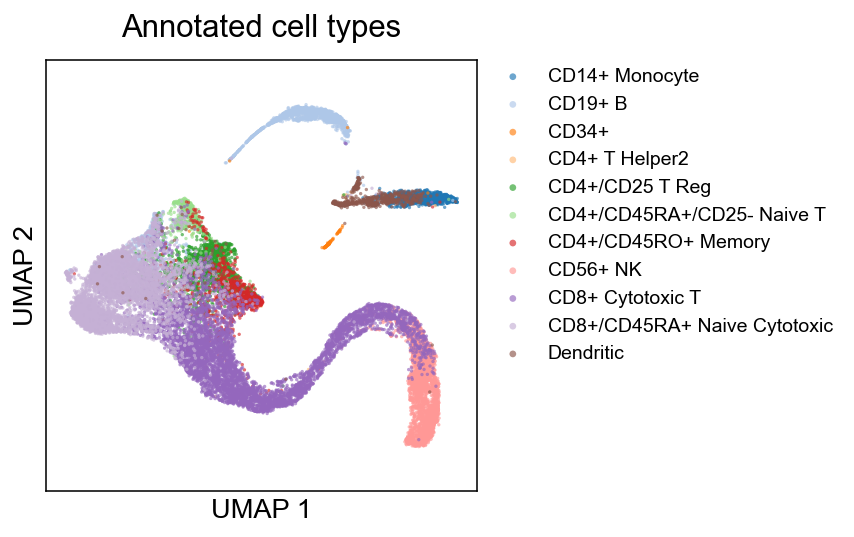

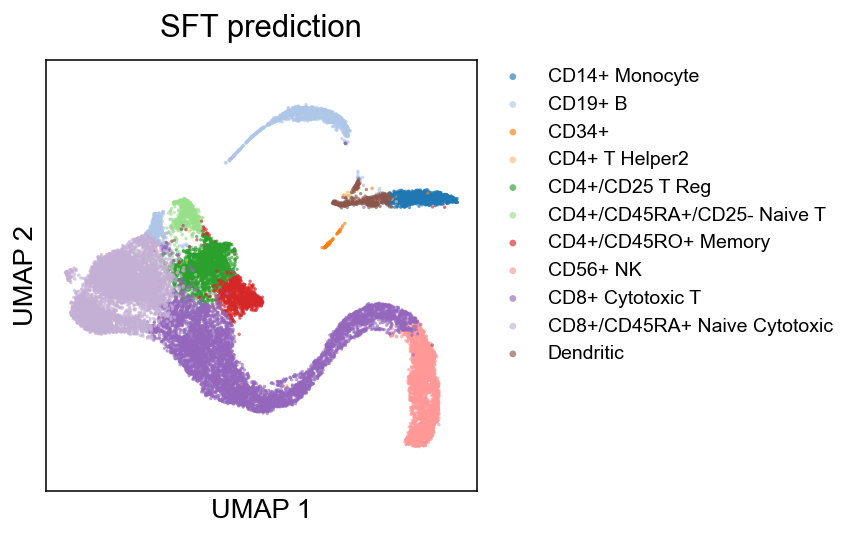

In [6]:
cell_types = list(predictions.class_names)
palette = plt.get_cmap("tab20")
cell_type_colors = {
    cell_type: palette(index) for index, cell_type in enumerate(cell_types)
}
embedding_adata = sc.AnnData(
    X=predictions.cell_embeddings.numpy(),
    obs=pd.DataFrame(index=test_adata.obs_names),
)
embedding_adata.obs["Annotated cell types"] = pd.Categorical(
    test_adata.obs[LABEL_KEY].astype(str), categories=cell_types
)
embedding_adata.obs["SFT prediction"] = pd.Categorical(
    predictions.predicted_labels, categories=cell_types
)
sc.pp.neighbors(
    embedding_adata, n_neighbors=15, use_rep="X",
    metric="cosine", random_state=RANDOM_STATE,
)
sc.tl.umap(embedding_adata, min_dist=0.3, random_state=RANDOM_STATE)

with plt.rc_context({
    "font.family": "Arial", "font.size": 14,
    "axes.titlesize": 16, "axes.labelsize": 14, "legend.fontsize": 10,
}):
    coordinates = embedding_adata.obsm["X_umap"]
    center = (coordinates.min(axis=0) + coordinates.max(axis=0)) / 2
    half_span = np.ptp(coordinates, axis=0).max() * 0.55
    for key in ["Annotated cell types", "SFT prediction"]:
        fig, ax = plt.subplots(figsize=(4, 4), dpi=140)
        for cell_type in cell_types:
            mask = (embedding_adata.obs[key] == cell_type).to_numpy()
            ax.scatter(
                coordinates[mask, 0], coordinates[mask, 1],
                s=3, alpha=0.65, edgecolors="none",
                color=cell_type_colors[cell_type], label=cell_type,
            )
        ax.set_title(key, fontsize=16, pad=12)
        ax.set_xlabel("UMAP 1", fontsize=14)
        ax.set_ylabel("UMAP 2", fontsize=14)
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlim(center[0] - half_span, center[0] + half_span)
        ax.set_ylim(center[1] - half_span, center[1] + half_span)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.legend(
            loc="upper left", bbox_to_anchor=(1.02, 1),
            frameon=False, markerscale=2, borderaxespad=0,
        )
        plt.show()


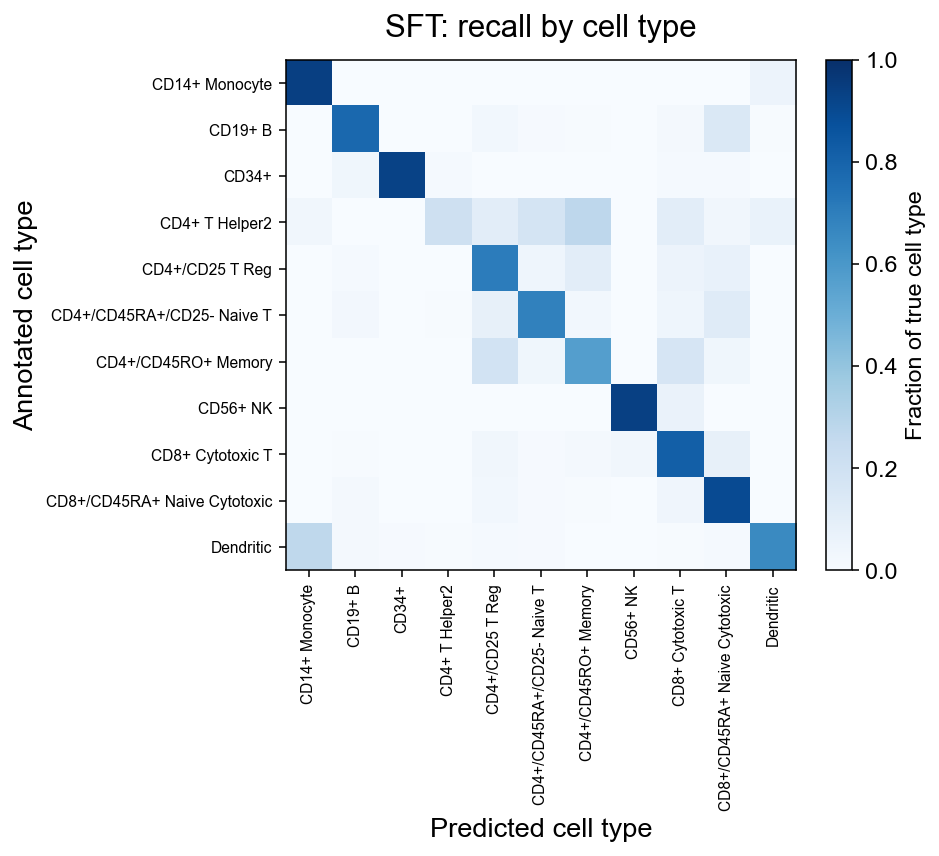

In [7]:
matrix = evaluation.confusion.to_numpy()
normalized_confusion = matrix / matrix.sum(axis=1, keepdims=True)

with plt.rc_context({"font.family": "Arial", "font.size": 12}):
    fig, ax = plt.subplots(figsize=(7, 6), dpi=140, layout="constrained")
    image = ax.imshow(normalized_confusion, cmap="Blues", vmin=0, vmax=1)
    ax.set_title("SFT: recall by cell type", fontsize=16, pad=12)
    ax.set_xlabel("Predicted cell type", fontsize=14)
    ax.set_ylabel("Annotated cell type", fontsize=14)
    ax.set_xticks(range(len(cell_types)), cell_types, rotation=90, fontsize=8)
    ax.set_yticks(range(len(cell_types)), cell_types, fontsize=8)
    fig.colorbar(image, ax=ax, label="Fraction of true cell type")
    plt.show()


## 6. Optional: save the annotator and prediction table

Export is disabled by default. When enabled, this saves the final-epoch classifier, the complete EFM embedding/backbone state, the global attention mode, class mapping, selected gene names and tokenizer configuration, plus a per-cell prediction table. Existing files are not overwritten.

`from_checkpoint()` restores the SFT annotator using the same pretrained SFM and vocabulary/resources. SFM is loaded from `model_source`. Apply the expression transformation and selected genes from section 3 before predicting on new raw data; checkpoint loading does not perform preprocessing. Figures are not saved externally.

For long training runs, `fit(training_checkpoint=...)` writes recovery state after each completed epoch. Restart with the same training inputs and settings and `resume_from=` that recovery file. This records optimizer, RNG and gene-order state so training can continue to the requested final epoch. It is separate from the inference checkpoint exported above.

In [8]:
SAVE_ANNOTATION_RESULTS = False

if SAVE_ANNOTATION_RESULTS:
    output_dir = REPO_ROOT / "results" / "cell_type_annotation"
    output_dir.mkdir(parents=True, exist_ok=True)
    annotator.save_checkpoint(output_dir / "pbmc_sft.pt")
    table = predictions.to_cell_table()
    table["true_cell_type"] = test_adata.obs[LABEL_KEY].astype(str).to_numpy()
    with (output_dir / "pbmc_sft_predictions.csv").open("x") as handle:
        table.to_csv(handle, index=False)

    restored_annotator = CellTypeAnnotator.from_checkpoint(
        output_dir / "pbmc_sft.pt",
        model_source=MODEL_SOURCE,
        device="cuda:0",
        attention_backend="fa4",
    )
    print("Saved the SFT annotator and prediction table.")
else:
    print("Export is disabled. Set SAVE_ANNOTATION_RESULTS = True to save results.")


Export is disabled. Set SAVE_ANNOTATION_RESULTS = True to save results.
